# Cargar el csv

In [1]:
import pandas as pd
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

In [2]:
orden_obesidad = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I',
                  'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']

C:\Users\mateo\AppData\Local\Temp\ipykernel_4248\3228882258.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', palette='pastel', ax=ax1)


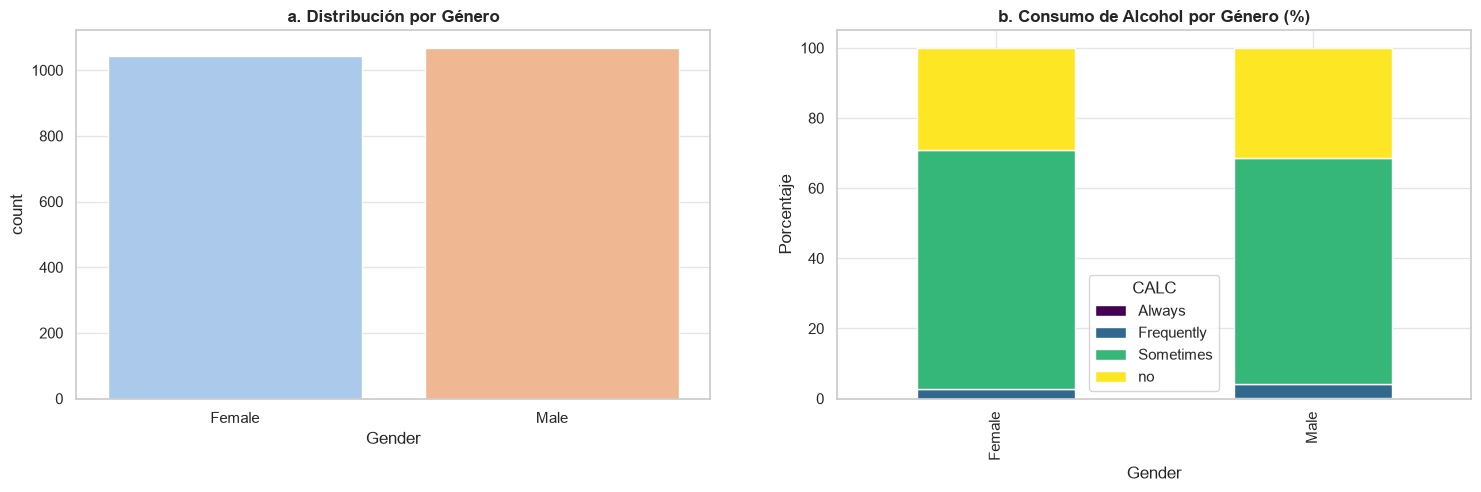

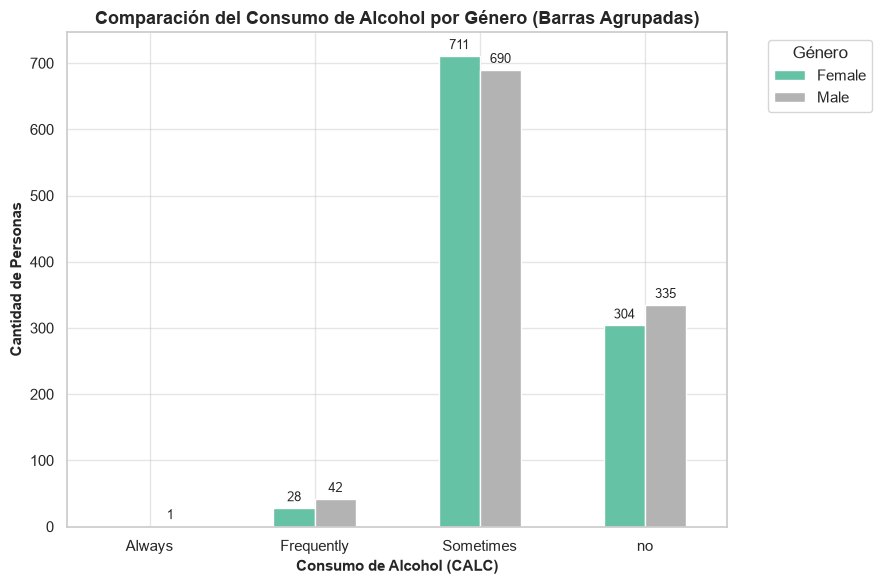

C:\Users\mateo\AppData\Local\Temp\ipykernel_4248\3228882258.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Gender', y='Age', palette='pastel', ax=ax6)
C:\Users\mateo\AppData\Local\Temp\ipykernel_4248\3228882258.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='NObeyesdad', y='Weight', order=orden_obesidad, palette='magma', ax=ax7)
C:\Users\mateo\AppData\Local\Temp\ipykernel_4248\3228882258.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='NObeyesdad', y='FCVC', order=orden_obesidad, palette='cr

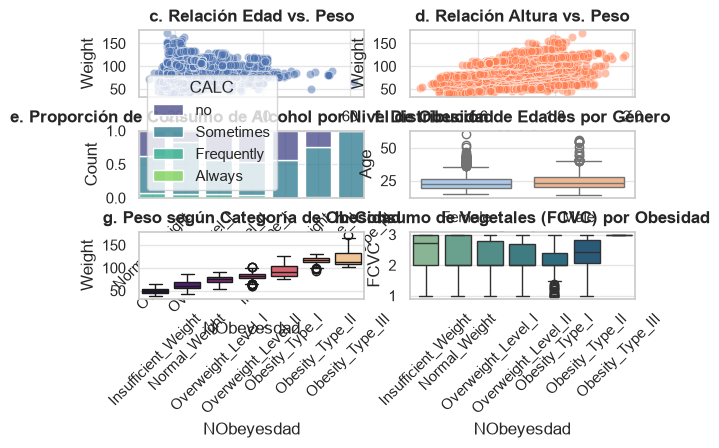

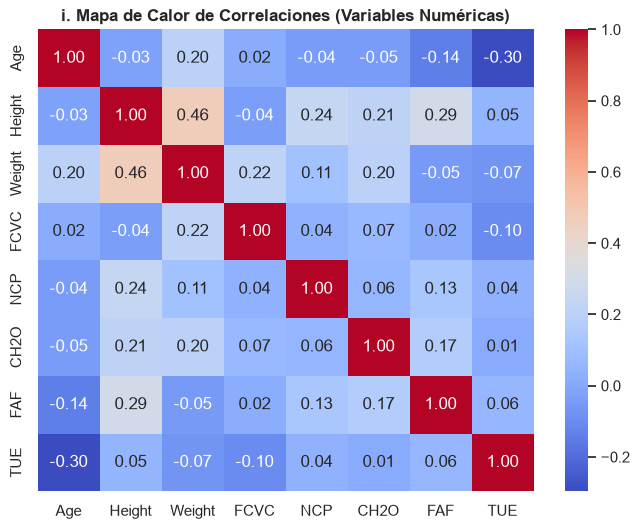

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Figura con subgráficos múltiples
fig = plt.figure(figsize=(18, 22))
fig.tight_layout(pad=6.0)

# a. Número de mujeres y hombres
ax1 = plt.subplot(4, 2, 1)
sns.countplot(data=df, x='Gender', palette='pastel', ax=ax1)
ax1.set_title('a. Distribución por Género', fontsize=12, fontweight='bold')

# b. Proporción de consumidores de alcohol por género
ax2 = plt.subplot(4, 2, 2)
calc_prop = pd.crosstab(df['Gender'], df['CALC'], normalize='index') * 100
calc_prop.plot(kind='bar', stacked=True, ax=ax2, colormap='viridis')
ax2.set_title('b. Consumo de Alcohol por Género (%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Porcentaje')

alc_gender_counts = pd.crosstab(df['CALC'], df['Gender'])

# Generar el gráfico de barras agrupadas (stacked=False)
ax = alc_gender_counts.plot(kind='bar', stacked=False, figsize=(9, 6), colormap='Set2')

# Agregar etiquetas, título y formato
plt.xlabel("Consumo de Alcohol (CALC)", fontsize=11, fontweight='bold')
plt.ylabel("Cantidad de Personas", fontsize=11, fontweight='bold')
plt.title("Comparación del Consumo de Alcohol por Género (Barras Agrupadas)", fontsize=13, fontweight='bold')

# Rotar las etiquetas del eje x para que se lean bien
plt.xticks(rotation=0)

# Agregar leyenda clara
plt.legend(title="Género", bbox_to_anchor=(1.05, 1), loc='upper left')

# Mostrar los valores exactos encima de las barras (opcional para mayor prolijidad)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 3), textcoords='offset points',
                    fontsize=9)

# Ajustar diseño y mostrar
plt.tight_layout()
plt.show()

# c. Relación entre edad y peso
ax3 = plt.subplot(4, 2, 3)
sns.scatterplot(data=df, x='Age', y='Weight', alpha=0.5, ax=ax3)
ax3.set_title('c. Relación Edad vs. Peso', fontsize=12, fontweight='bold')

# d. Relación entre peso y altura
ax4 = plt.subplot(4, 2, 4)
sns.scatterplot(data=df, x='Height', y='Weight', alpha=0.5, color='coral', ax=ax4)
ax4.set_title('d. Relación Altura vs. Peso', fontsize=12, fontweight='bold')

# e. Relación obesidad y alcohol
ax5 = plt.subplot(4, 2, 5)
sns.histplot(data=df, x='NObeyesdad', hue='CALC', multiple='fill', palette='viridis', shrink=0.8, ax=ax5)
ax5.set_title('e. Proporción de Consumo de Alcohol por Nivel de Obesidad', fontsize=12, fontweight='bold')
ax5.tick_params(axis='x', rotation=45)

# f. Proporción de edades entre hombres y mujeres
ax6 = plt.subplot(4, 2, 6)
sns.boxplot(data=df, x='Gender', y='Age', palette='pastel', ax=ax6)
ax6.set_title('f. Distribución de Edades por Género', fontsize=12, fontweight='bold')

# g. Valores de peso por categoría de obesidad
ax7 = plt.subplot(4, 2, 7)
sns.boxplot(data=df, x='NObeyesdad', y='Weight', order=orden_obesidad, palette='magma', ax=ax7)
ax7.set_title('g. Peso según Categoría de Obesidad', fontsize=12, fontweight='bold')
ax7.tick_params(axis='x', rotation=45)

# h. Relación entre consumo de vegetales (FCVC) y obesidad
ax8 = plt.subplot(4, 2, 8)
sns.boxplot(data=df, x='NObeyesdad', y='FCVC', order=orden_obesidad, palette='crest', ax=ax8)
ax8.set_title('h. Consumo de Vegetales (FCVC) por Obesidad', fontsize=12, fontweight='bold')
ax8.tick_params(axis='x', rotation=45)

plt.subplots_adjust(hspace=0.5)
plt.show()

# i. Gráfica adicional propuesta 1: Heatmap de correlaciones numéricas
plt.figure(figsize=(8, 6))
cols_num = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
sns.heatmap(df[cols_num].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('i. Mapa de Calor de Correlaciones (Variables Numéricas)', fontsize=12, fontweight='bold')
plt.show()